# Lab 03 - Developing a Tiny Transformer Language Model

In [1]:
!pip install -q datasets

import torch, math, time, random
import torch.nn as nn
from torch.nn import functional as F
import matplotlib.pyplot as plt

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

PyTorch version: 2.14.1+cu130
GPU available: True
GPU name: Tesla T4
Using device: cuda


README.md:   0%|          | 0.00/1.06k [00:00<?, ?B/s]

Number of stories loaded: 20000

--- Story 1 ---
One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on her shirt.

Lily went to her mom and said, "Mom, I found this needle. Can you share it with me and sew my shirt?" Her mom smiled and said, "Yes, Lily, we can share the needle and fix your shirt."

Together, they shared the needle and sewed the button on Lily's shirt. It was not difficult for them because they were sharing and helping each other. After they finished, Lily thanked her mom for sharing the needle and fixing her shirt. They both felt happy because they had shared and worked together.

--- Story 2 ---
Once upon a time, there was a little car named Beep. Beep loved to go fast and play in the sun. Beep was a healthy car because he always had good fuel. Good fuel made Beep happy and strong.

One day, Beep was driving in the park whe

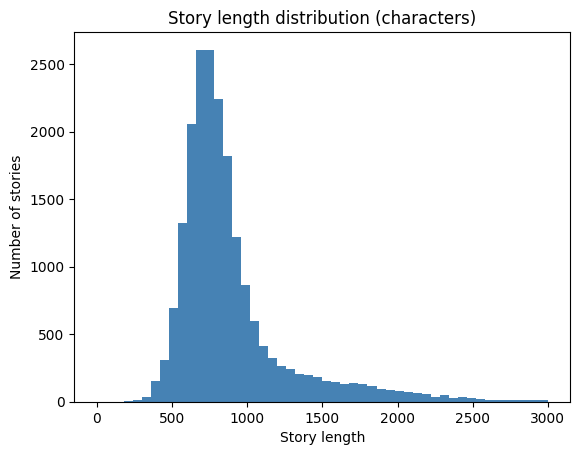

In [2]:
from datasets import load_dataset

# Stream the dataset so we do not download all 2 million stories
dataset = load_dataset("roneneldan/TinyStories", split="train", streaming=True)
stories = [row["text"] for _, row in zip(range(20000), dataset)]

print("Number of stories loaded:", len(stories))
print()

for i in range(3):
    print(f"--- Story {i+1} ---")
    print(stories[i])
    print()

lengths = [len(s) for s in stories]
print("Shortest story (characters):", min(lengths))
print("Longest story (characters):", max(lengths))
print("Average story length (characters):", round(sum(lengths) / len(lengths)))

plt.hist(lengths, bins=50, range=(0, 3000), color="steelblue")
plt.title("Story length distribution (characters)")
plt.xlabel("Story length")
plt.ylabel("Number of stories")
plt.show()

In [3]:
# Task 2: choose a small subset of stories and tokenize at character level
subset = stories[:5000]
text = "\n\n".join(subset)
print("Total characters in subset:", len(text))

# Vocabulary = every different character that appears
chars = sorted(set(text))
vocab_size = len(chars)
print("Vocabulary size (different characters):", vocab_size)
print("Characters:", "".join(chars))

# Character <-> number lookup tables
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for ch, i in stoi.items()}
encode = lambda s: [stoi[c] for c in s]
decode = lambda l: "".join(itos[i] for i in l)

# Test it
sample = "Once upon a time"
print()
print("Original text :", sample)
print("As numbers    :", encode(sample))
print("Back to text  :", decode(encode(sample)))

# Convert the whole text to numbers and split 90% train / 10% validation
data = torch.tensor(encode(text), dtype=torch.long)
n = int(0.9 * len(data))
train_data, val_data = data[:n], data[n:]
print()
print("Training tokens  :", len(train_data))
print("Validation tokens:", len(val_data))

Total characters in subset: 4186738
Vocabulary size (different characters): 90
Characters: 
 !"$',-.0123456789:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz¡¦©«±³»ÂÃâœ˜“”€™

Original text : Once upon a time
As numbers    : [36, 61, 50, 52, 1, 68, 63, 62, 61, 1, 48, 1, 67, 56, 60, 52]
Back to text  : Once upon a time

Training tokens  : 3768064
Validation tokens: 418674


In [4]:
# Task 3: input sequences and target sequences for next-token prediction
block_size = 128   # how many characters the model looks at
batch_size = 64    # how many examples it learns from at once

def get_batch(split):
    d = train_data if split == "train" else val_data
    ix = torch.randint(len(d) - block_size, (batch_size,))
    x = torch.stack([d[i:i + block_size] for i in ix])          # input
    y = torch.stack([d[i + 1:i + block_size + 1] for i in ix])  # target = input shifted by 1
    return x.to(device), y.to(device)

xb, yb = get_batch("train")
print("Input batch shape :", xb.shape)
print("Target batch shape:", yb.shape)
print()
print("What the model practises on (first example):")
for t in range(8):
    context = xb[0, :t + 1].tolist()
    target = yb[0, t].item()
    print(f"Input: {repr(decode(context)):12}  ->  next character: {repr(decode([target]))}")

Input batch shape : torch.Size([64, 128])
Target batch shape: torch.Size([64, 128])

What the model practises on (first example):
Input: 'e'           ->  next character: 'r'
Input: 'er'          ->  next character: 'v'
Input: 'erv'         ->  next character: 'e'
Input: 'erve'        ->  next character: 'd'
Input: 'erved'       ->  next character: ' '
Input: 'erved '      ->  next character: 'a'
Input: 'erved a'     ->  next character: ' '
Input: 'erved a '    ->  next character: 'b'


In [5]:
# Task 4: Build the Transformer architecture

# Model settings
n_embd  = 128   # size of the number-list used to represent each character
n_head  = 4     # number of attention heads
n_layer = 4     # number of Transformer blocks stacked on top of each other
dropout = 0.1   # randomly switches off some connections while training to reduce overfitting


class CausalSelfAttention(nn.Module):
    """Masked multi-head self-attention."""
    def __init__(self, n_embd, n_head, block_size, dropout):
        super().__init__()
        assert n_embd % n_head == 0
        self.n_head = n_head
        self.qkv = nn.Linear(n_embd, 3 * n_embd)   # makes query, key and value
        self.proj = nn.Linear(n_embd, n_embd)
        self.attn_drop = nn.Dropout(dropout)
        self.resid_drop = nn.Dropout(dropout)
        # The mask: each position may only look at earlier positions, never the future
        mask = torch.tril(torch.ones(block_size, block_size)).view(1, 1, block_size, block_size)
        self.register_buffer("mask", mask)

    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.qkv(x).split(C, dim=2)
        q = q.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        k = k.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        v = v.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        att = (q @ k.transpose(-2, -1)) / math.sqrt(k.size(-1))     # how much each token cares about each other token
        att = att.masked_fill(self.mask[:, :, :T, :T] == 0, float("-inf"))  # hide the future
        att = F.softmax(att, dim=-1)
        att = self.attn_drop(att)
        y = att @ v
        y = y.transpose(1, 2).contiguous().view(B, T, C)
        return self.resid_drop(self.proj(y))


class FeedForward(nn.Module):
    """Small neural network that processes what attention found."""
    def __init__(self, n_embd, dropout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.GELU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)


class Block(nn.Module):
    """One Transformer block = attention + feed-forward, with layer norm and residual connections."""
    def __init__(self, n_embd, n_head, block_size, dropout):
        super().__init__()
        self.ln1 = nn.LayerNorm(n_embd)
        self.attn = CausalSelfAttention(n_embd, n_head, block_size, dropout)
        self.ln2 = nn.LayerNorm(n_embd)
        self.ffwd = FeedForward(n_embd, dropout)

    def forward(self, x):
        x = x + self.attn(self.ln1(x))   # residual connection
        x = x + self.ffwd(self.ln2(x))   # residual connection
        return x


class TinyTransformer(nn.Module):
    def __init__(self, vocab_size, block_size, n_embd, n_head, n_layer, dropout):
        super().__init__()
        self.block_size = block_size
        self.token_embedding = nn.Embedding(vocab_size, n_embd)      # what each character is
        self.position_embedding = nn.Embedding(block_size, n_embd)   # where each character is
        self.drop = nn.Dropout(dropout)
        self.blocks = nn.Sequential(*[Block(n_embd, n_head, block_size, dropout) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size)                 # scores for every possible next character

    def forward(self, idx, targets=None):
        B, T = idx.shape
        tok = self.token_embedding(idx)
        pos = self.position_embedding(torch.arange(T, device=idx.device))
        x = self.drop(tok + pos)
        x = self.blocks(x)
        x = self.ln_f(x)
        logits = self.lm_head(x)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0):
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.block_size:]
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :] / temperature
            probs = F.softmax(logits, dim=-1)
            next_id = torch.multinomial(probs, num_samples=1)
            idx = torch.cat((idx, next_id), dim=1)
        return idx

print("Transformer architecture defined.")

Transformer architecture defined.


In [6]:
# Task 5: Initialize the model, loss function and optimizer
model = TinyTransformer(vocab_size, block_size, n_embd, n_head, n_layer, dropout).to(device)

learning_rate = 1e-3
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)
# Loss function: cross-entropy (used inside the model's forward function)

num_params = sum(p.numel() for p in model.parameters())
print("Number of parameters:", f"{num_params:,}")
print("Layers:", n_layer, "| Attention heads:", n_head, "| Embedding size:", n_embd)

# Sanity check: an untrained model is guessing randomly, so its loss should be close to ln(vocab_size)
xb, yb = get_batch("train")
model.eval()
with torch.no_grad():
    _, loss = model(xb, yb)
print()
print("Loss before training :", round(loss.item(), 3))
print("Random-guess loss    :", round(math.log(vocab_size), 3), "(= ln of vocabulary size)")

Number of parameters: 832,858
Layers: 4 | Attention heads: 4 | Embedding size: 128

Loss before training : 4.703
Random-guess loss    : 4.5 (= ln of vocabulary size)


In [7]:
# Tasks 6 and 7: Train the model and record training / validation loss

@torch.no_grad()
def estimate_loss(model, eval_iters=50):
    """Average loss on training data and on validation data the model has never trained on."""
    model.eval()
    out = {}
    for split in ["train", "val"]:
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            xb, yb = get_batch(split)
            _, loss = model(xb, yb)
            losses[k] = loss.item()
        out[split] = losses.mean().item()
    model.train()
    return out


def train_model(model, optimizer, max_iters=3000, eval_interval=250):
    history = {"steps": [], "train": [], "val": []}
    start = time.time()
    model.train()
    for it in range(max_iters + 1):
        # Every few steps, record the losses
        if it % eval_interval == 0:
            l = estimate_loss(model)
            history["steps"].append(it)
            history["train"].append(l["train"])
            history["val"].append(l["val"])
            print(f"step {it:5d} | train loss {l['train']:.4f} | val loss {l['val']:.4f} | time {time.time() - start:.0f}s")
        if it == max_iters:
            break
        # The learning step
        xb, yb = get_batch("train")
        logits, loss = model(xb, yb)                 # 1. predict the next characters + calculate cross-entropy loss
        optimizer.zero_grad(set_to_none=True)
        loss.backward()                              # 2. backpropagation: work out how to improve
        optimizer.step()                             # 3. update the model's parameters
    print(f"Training finished in {time.time() - start:.0f} seconds")
    return history


steps_per_epoch = len(train_data) // (batch_size * block_size)
print(f"One epoch is about {steps_per_epoch} steps, so 3000 steps is about {3000 / steps_per_epoch:.1f} epochs")
print()

history_main = train_model(model, optimizer, max_iters=3000, eval_interval=250)

One epoch is about 459 steps, so 3000 steps is about 6.5 epochs

step     0 | train loss 4.7133 | val loss 4.7123 | time 2s
step   250 | train loss 2.0496 | val loss 2.0766 | time 13s
step   500 | train loss 1.5846 | val loss 1.6048 | time 24s
step   750 | train loss 1.3863 | val loss 1.4038 | time 35s
step  1000 | train loss 1.2837 | val loss 1.2950 | time 45s
step  1250 | train loss 1.2098 | val loss 1.2235 | time 54s
step  1500 | train loss 1.1640 | val loss 1.1776 | time 64s
step  1750 | train loss 1.1173 | val loss 1.1456 | time 74s
step  2000 | train loss 1.0975 | val loss 1.1140 | time 84s
step  2250 | train loss 1.0713 | val loss 1.0926 | time 95s
step  2500 | train loss 1.0512 | val loss 1.0770 | time 105s
step  2750 | train loss 1.0298 | val loss 1.0629 | time 115s
step  3000 | train loss 1.0180 | val loss 1.0449 | time 125s
Training finished in 125 seconds


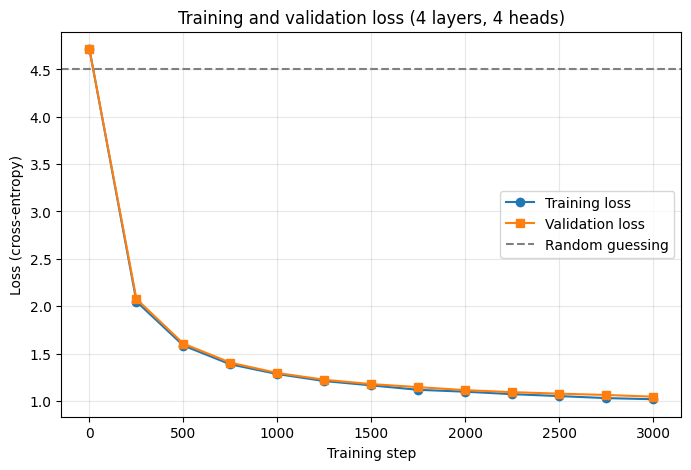

Starting loss : 4.712
Final train loss     : 1.018
Final validation loss: 1.045


In [8]:
# Task 7: Plot the training and validation loss curves
plt.figure(figsize=(8, 5))
plt.plot(history_main["steps"], history_main["train"], label="Training loss", marker="o")
plt.plot(history_main["steps"], history_main["val"], label="Validation loss", marker="s")
plt.axhline(math.log(vocab_size), color="grey", linestyle="--", label="Random guessing")
plt.title("Training and validation loss (4 layers, 4 heads)")
plt.xlabel("Training step")
plt.ylabel("Loss (cross-entropy)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("Starting loss :", round(history_main["val"][0], 3))
print("Final train loss     :", round(history_main["train"][-1], 3))
print("Final validation loss:", round(history_main["val"][-1], 3))

In [9]:
# Task 8: Evaluate the model - validation loss and perplexity
final = estimate_loss(model, eval_iters=200)   # more batches = a steadier estimate

val_loss = final["val"]
train_loss = final["train"]
perplexity = math.exp(val_loss)

start_val_loss = history_main["val"][0]
start_perplexity = math.exp(start_val_loss)

print(f"Training loss    : {train_loss:.4f}")
print(f"Validation loss  : {val_loss:.4f}")
print(f"Perplexity (after training) : {perplexity:.2f}")
print()
print(f"Perplexity before training  : {start_perplexity:.2f}")
print(f"Vocabulary size (random guessing would be about this): {vocab_size}")

Training loss    : 1.0207
Validation loss  : 1.0483
Perplexity (after training) : 2.85

Perplexity before training  : 111.30
Vocabulary size (random guessing would be about this): 90


In [10]:
# Task 9: Generate stories from a starting prompt
def generate_story(prompt, max_new_tokens=350, temperature=0.8):
    model.eval()
    idx = torch.tensor([encode(prompt)], dtype=torch.long, device=device)
    out = model.generate(idx, max_new_tokens=max_new_tokens, temperature=temperature)
    return decode(out[0].tolist())

torch.manual_seed(42)

prompts = [
    "Once upon a time",
    "One day, a little girl named",
    "The dog was very happy because",
]

for p in prompts:
    print("PROMPT:", p)
    print("-" * 60)
    print(generate_story(p))
    print()
    print("=" * 60)
    print()

PROMPT: Once upon a time
------------------------------------------------------------
Once upon a time, there were two stopped with their face. So he loved to wear something so special first, but he was so sad. He was very deep playing the ground. He had a truck flowers, but she also very sad. 

Something her mom said, "I want to follow a dog the tree with it make such a lot of fun, they were felt them. But then he repeaded the tree.

The farmer wa


PROMPT: One day, a little girl named
------------------------------------------------------------
One day, a little girl named Sue woods her. There was a girl who lived in a longer. From then, they felt sorry, Max's dog outside and time to there was a big, belonger little girl named Bob. It was always very because it was proud and clear over to the boy. He loved to play with his own brothers. 

Suddenly, Jack's mom kind and began to find the birds down. They wanted to pla


PROMPT: The dog was very happy because
---------------------------

In [11]:
# Extra: effect of temperature on the generated text
for temp in [0.4, 0.8, 1.3]:
    torch.manual_seed(7)
    print(f"TEMPERATURE = {temp}")
    print("-" * 60)
    print(generate_story("Once upon a time", max_new_tokens=250, temperature=temp))
    print()
    print("=" * 60)
    print()

TEMPERATURE = 0.4
------------------------------------------------------------
Once upon a time, there was a little girl named Lily. She was very happy to see the one of the trees. He went outside to the sky. She was very happy that he was so happy. She was so excited to have fun.

Sam and her mom went to the park and saw a plant to the park. 


TEMPERATURE = 0.8
------------------------------------------------------------
Once upon a time, there was a kind. It was a great courful with her friend decided to always very excited!

"Mom, I will always so proud of promise. It is not get your. It was strong happy and talking in the forest." 

The table was very began to play with the water


TEMPERATURE = 1.3
------------------------------------------------------------
Once upon a time, there was a kazing police song! Graceful, took the othined grouble named Sometiveding soments, also tell, but shippied icep”.

"It's mommy might. There!" Mom says, ”mliched red words what many cute. They kno

In [12]:
# Task 10: Experiment with model settings
def sample_text(m, prompt="Once upon a time", n=200, temperature=0.8):
    m.eval()
    idx = torch.tensor([encode(prompt)], dtype=torch.long, device=device)
    out = m.generate(idx, max_new_tokens=n, temperature=temperature)
    return decode(out[0].tolist())

results = {}

# Baseline: the model we already trained (4 layers, 4 heads)
torch.manual_seed(7)
results["4 layers, 4 heads (baseline)"] = {
    "params": sum(p.numel() for p in model.parameters()),
    "train_loss": train_loss,
    "val_loss": val_loss,
    "perplexity": perplexity,
    "time": 125,                      # seconds, measured in the earlier training run
    "history": history_main,
    "sample": sample_text(model),
}

experiments = [
    {"name": "1 layer, 4 heads",  "n_layer": 1, "n_head": 4},
    {"name": "8 layers, 4 heads", "n_layer": 8, "n_head": 4},
    {"name": "4 layers, 1 head",  "n_layer": 4, "n_head": 1},
    {"name": "4 layers, 8 heads", "n_layer": 4, "n_head": 8},
]

for cfg in experiments:
    print("#" * 60)
    print("EXPERIMENT:", cfg["name"])
    print("#" * 60)
    torch.manual_seed(1337)
    m = TinyTransformer(vocab_size, block_size, n_embd, cfg["n_head"], cfg["n_layer"], dropout).to(device)
    opt = torch.optim.AdamW(m.parameters(), lr=learning_rate)
    t0 = time.time()
    hist = train_model(m, opt, max_iters=3000, eval_interval=500)
    elapsed = time.time() - t0
    fin = estimate_loss(m, eval_iters=200)
    torch.manual_seed(7)
    results[cfg["name"]] = {
        "params": sum(p.numel() for p in m.parameters()),
        "train_loss": fin["train"],
        "val_loss": fin["val"],
        "perplexity": math.exp(fin["val"]),
        "time": round(elapsed),
        "history": hist,
        "sample": sample_text(m),
    }
    print()
    print("Sample story from this model:")
    print(results[cfg["name"]]["sample"])
    print()

print("All experiments finished.")

############################################################
EXPERIMENT: 1 layer, 4 heads
############################################################
step     0 | train loss 4.6892 | val loss 4.6896 | time 0s
step   500 | train loss 1.8360 | val loss 1.8584 | time 6s
step  1000 | train loss 1.5233 | val loss 1.5451 | time 11s
step  1500 | train loss 1.4083 | val loss 1.4298 | time 17s
step  2000 | train loss 1.3435 | val loss 1.3622 | time 22s
step  2500 | train loss 1.3102 | val loss 1.3256 | time 28s
step  3000 | train loss 1.2847 | val loss 1.3114 | time 33s
Training finished in 33 seconds

Sample story from this model:
Once upon a time, they had saw a little get are wanted to the stranger and stranger. They saw something so her for she was very smiled and mazed it was so excited. They back to the other. Can explore surprise a littl

############################################################
EXPERIMENT: 8 layers, 4 heads
###########################################################

                     Setting Parameters  Train loss  Validation loss  Perplexity  Time (s)
4 layers, 4 heads (baseline)    832,858       1.021            1.048        2.85       125
            1 layer, 4 heads    238,042       1.284            1.308        3.70        33
           8 layers, 4 heads  1,625,946       0.933            0.969        2.64       224
            4 layers, 1 head    832,858       1.056            1.081        2.95        88
           4 layers, 8 heads    832,858       1.024            1.054        2.87       144


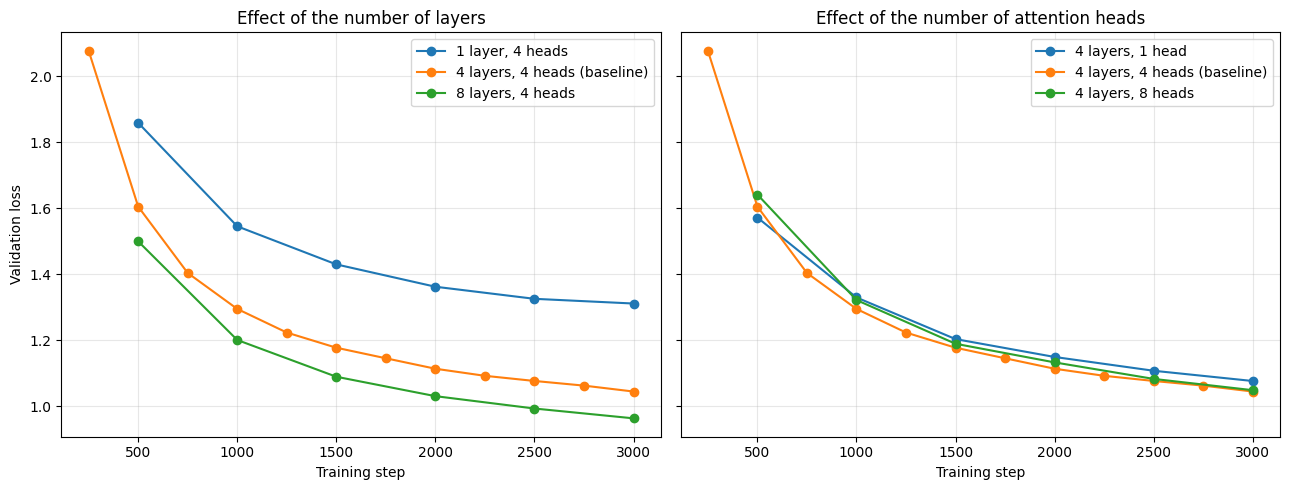


Effect of training length (4 layers, 4 heads):
    250 steps (about 0.5 epochs): validation loss 2.077
    500 steps (about 1.1 epochs): validation loss 1.605
   1000 steps (about 2.2 epochs): validation loss 1.295
   2000 steps (about 4.4 epochs): validation loss 1.114
   3000 steps (about 6.5 epochs): validation loss 1.045


In [13]:
import pandas as pd

# Comparison table
rows = []
for name, r in results.items():
    rows.append({
        "Setting": name,
        "Parameters": f"{r['params']:,}",
        "Train loss": round(r["train_loss"], 3),
        "Validation loss": round(r["val_loss"], 3),
        "Perplexity": round(r["perplexity"], 2),
        "Time (s)": r["time"],
    })
table = pd.DataFrame(rows)
print(table.to_string(index=False))

# Charts: validation loss over training
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
layer_runs = ["1 layer, 4 heads", "4 layers, 4 heads (baseline)", "8 layers, 4 heads"]
head_runs  = ["4 layers, 1 head", "4 layers, 4 heads (baseline)", "4 layers, 8 heads"]

for ax, runs, title in zip(axes, [layer_runs, head_runs],
                           ["Effect of the number of layers", "Effect of the number of attention heads"]):
    for name in runs:
        h = results[name]["history"]
        ax.plot(h["steps"][1:], h["val"][1:], marker="o", label=name)   # skip step 0 so the chart is easier to read
    ax.set_title(title)
    ax.set_xlabel("Training step")
    ax.grid(alpha=0.3)
    ax.legend()
axes[0].set_ylabel("Validation loss")
plt.tight_layout()
plt.show()

# Effect of training length (same baseline model, measured at different steps)
print()
print("Effect of training length (4 layers, 4 heads):")
for s, v in zip(history_main["steps"], history_main["val"]):
    if s in (250, 500, 1000, 2000, 3000):
        print(f"  {s:5d} steps (about {s / steps_per_epoch:.1f} epochs): validation loss {v:.3f}")

In [14]:
# Task 11: Save the trained model parameters and configuration
import json
import os
from google.colab import files

# 1. Save the learned parameters (weights)
torch.save(model.state_dict(), "tiny_transformer_weights.pt")

# 2. Save the configuration (settings + character lookup table)
config = {
    "vocab_size": vocab_size,
    "block_size": block_size,
    "n_embd": n_embd,
    "n_head": n_head,
    "n_layer": n_layer,
    "dropout": dropout,
    "stoi": stoi,
}
with open("tiny_transformer_config.json", "w") as f:
    json.dump(config, f)

print("Saved files:")
for fname in ["tiny_transformer_weights.pt", "tiny_transformer_config.json"]:
    print(f"  {fname}  ({os.path.getsize(fname) / 1024:.1f} KB)")

# 3. Prove it works: build a NEW model, load the saved parameters, and generate text
with open("tiny_transformer_config.json") as f:
    cfg = json.load(f)

loaded = TinyTransformer(cfg["vocab_size"], cfg["block_size"], cfg["n_embd"],
                         cfg["n_head"], cfg["n_layer"], cfg["dropout"]).to(device)
loaded.load_state_dict(torch.load("tiny_transformer_weights.pt", map_location=device))
loaded.eval()

torch.manual_seed(7)
text_loaded = sample_text(loaded)
same = (text_loaded == results["4 layers, 4 heads (baseline)"]["sample"])

print()
print("Story from the reloaded model:")
print(text_loaded)
print()
print("Identical to the original model's story:", same)

# 4. Download the files to your computer
files.download("tiny_transformer_weights.pt")
files.download("tiny_transformer_config.json")

Saved files:
  tiny_transformer_weights.pt  (3531.0 KB)
  tiny_transformer_config.json  (1.0 KB)

Story from the reloaded model:
Once upon a time, there was a kind. It was a great courful with her friend decided to always very excited!

"Mom, I will always so proud of promise. It is not get your. It was strong happy and talking in the forest."

Identical to the original model's story: True


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>